# 01 · Datos, exploración y variables previas

Intentamos estimar las faltas de cada equipo antes de jugar. Empezamos definiendo la respuesta,
comprobamos los datos y construimos información previa utilizable. Tener muchas entradas no
asegura predecir mejor: su utilidad se contrastará después.

**Captura del estudio:** 20 de octubre de 2026, temporada **2026/27 hasta J9**: **88 partidos
finalizados**. El desarrollo utiliza los **59 de las jornadas 1–6**; los **29 restantes** forman
el contraste temporal. El análisis es retrospectivo: este contraste no se presenta como un test
ciego independiente de toda la exploración. Los recuentos reales se muestran al cargar los datos.

**Distribución pública.** Se conservan las explicaciones y los resultados agregados del estudio. Los CSV reales y las salidas de partidos individuales no se incluyen. Para ejecutar las celdas, prepara primero tus datos en `data/local/actualizados` siguiendo [docs/guia_de_uso.md](../docs/guia_de_uso.md). Obtener otra captura no garantiza las mismas métricas.


In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "2")
RAIZ = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
assert (RAIZ/"src/faltas").is_dir(), "Abre el notebook desde la carpeta del proyecto o notebooks/."
sys.path.insert(0, str(RAIZ/"src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from faltas.util import leer_json
from faltas.datos import datos_por_defecto, cargar_datos
from faltas.investigacion.biblioteca import tabla, mostrar, imagen, resumen_hipotesis
from faltas.entrega import cobertura, INFORMES_ACTUALES
get_ipython().run_line_magic("matplotlib", "inline")
CARPETA_ACTUALIZADA = RAIZ/"data/local/actualizados"
DATOS = (datos_por_defecto() if os.environ.get("FALTAS_DATOS") else
         CARPETA_ACTUALIZADA if CARPETA_ACTUALIZADA.exists() else datos_por_defecto())
d = cargar_datos(DATOS)
INFO_DATOS = cobertura(d)
print("Carpeta de datos elegida:", DATOS.relative_to(RAIZ) if DATOS.is_relative_to(RAIZ) else DATOS)
print("Captura:", INFO_DATOS["captura_utc"], "| Hasta jornada:", INFO_DATOS["jornada_hasta"])
print("Partidos actuales:", INFO_DATOS["partidos_actuales"], "| Historial finalizado:", INFO_DATOS["partidos_finalizados"])
INFORMES = RAIZ/"reports/investigacion"
if d.huella != leer_json(RAIZ/"config/diseno_estudio.json")["huella_datos"]:
    print("Los CSV elegidos difieren de la captura del estudio: las tablas archivadas siguen siendo V1 hasta J9.")

Carpeta de datos elegida: data\local\estudio_v1
Captura: 2026-10-20T10:36:55Z | Hasta jornada: 9
Partidos actuales: 88 | Historial finalizado: 1228


<a id="datos"></a>
## 1. Objetivo y tablas de entrada

Predecimos faltas cometidas en el partido completo. Cada encuentro genera dos observaciones,
una por equipo; el total previsto es su suma. Faltas recibidas son las cometidas por el rival.
Recibimos seis CSV enlazados por identificadores, con tres temporadas anteriores y la actual.
[docs/datos.md](../docs/datos.md) define columnas, unidades y relaciones.

In [2]:
from faltas.datos import resumen_datos
mostrar("Cobertura por temporada", resumen_datos(d).reset_index(), abierto=True)
esquema=leer_json(RAIZ/"config/esquema.json")["tablas"]
mostrar("Claves, filas y columnas", pd.DataFrame([dict(tabla=n,filas=len(d.tablas[n]),columnas=len(v["columnas"]),clave=", ".join(v["pk"])) for n,v in esquema.items()]))

temporada,partidos,finalizados
2023/24,380,380
2024/25,380,380
2025/26,380,380
2026/27,100,88


tabla,filas,columnas,clave
equipos,29,3,id_equipo
partidos,1240,11,id_partido
estadisticas,1228,24,id_estadistica
arbitros,29,3,id_arbitro
designaciones,1220,8,id_designacion
fuentes,1244,9,id_fuente


<a id="fuentes"></a>
## 2. Calidad: qué comprobamos y qué sigue pendiente

La lectura valida cabeceras, tipos, fechas con zona horaria, claves, relaciones y suma de faltas.
Los errores de contrato detienen la carga; los desconocidos no se convierten en cero. Se conservan
los extremos para medir también sus errores. Quedan 28 discrepancias documentadas pendientes de
contraste. Una revisión dirigida de cuatro casos confirmó tres cifras y no pudo consultar
la cuarta ficha. Estos controles no certifican todas las cifras de las fuentes.

In [3]:
mostrar("Política de etiquetas y fuentes", pd.DataFrame([leer_json(RAIZ/"config/experimentos/politica_etiquetas.json")]))
mostrar("Ausencias de estadísticas", d.tablas["estadisticas"].isna().sum().rename("ausentes").reset_index().rename(columns={"index":"campo"}))
mostrar("Incidencias de las fuentes", d.tablas["fuentes"])
print("Validaciones de formato, relaciones y coherencia superadas al cargar los seis CSV.")

version,objetivo,unidad,semantica_recibidas_en_variables,fuente_prioritaria,fuente_complementaria,referencia_definiciones,adjudicacion,captura_estudio,decision_estudio,contraste_dirigido,correcciones_futuras,reserva,limitaciones
faltas-canonicas-v1,"Faltas cometidas por un equipo en el partido de liga completo: 90 minutos más descuento, sin prórroga ni penaltis de desempate.",Recuento entero no negativo por equipo; total del partido = local + visitante.,"Es el recuento de faltas cometidas por el rival en ese encuentro. Es una variable derivada del espejo, no una medición independiente de faltas sufridas.","Ficha de estadísticas del partido de LALIGA, identificando competición, temporada, equipos, localía y fecha.","Football-Data.co.uk: HF = faltas cometidas local, AF = faltas cometidas visitante; no usar HFKC/AFKC (tiros libres concedidos) ni sumar fueras de juego.",https://football-data.co.uk/notes.txt,"Si ambas fuentes discrepan, conservar el par de cifras oficial documentado, registrar las dos versiones, URL, fecha de consulta y motivo. No escoger la cifra que haga menor el error del modelo. Si no puede verificarse, mantener estado pendiente explícito.",Captura privada del estudio (no distribuida),Se conservan las etiquetas de la captura privada del estudio y sus incidencias para comparar métodos sobre las mismas respuestas. No se certifican todas las fuentes.,La revisión muestral y sus limitaciones se documentan en docs/experimentos/cierre_auditoria.md.,Crear una versión nueva con evidencia y registro de valores antiguos/nuevos. Recalcular variables y desarrollo si afecta a su preparación. No sustituir silenciosamente la captura ni corregir etiquetas según los errores del test.,No elegir etiquetas o correcciones para favorecer las métricas de un modelo; registrar fuentes e incidencias.,"[La comprobación externa es muestral; no se declaran verificados todos los partidos., Inicio + 24 horas es un supuesto de disponibilidad para el backtest, no una publicación histórica acreditada., Las condiciones de liquidación de una casa de apuestas no forman parte de esta definición ni se han contrastado.]"


campo,ausentes
id_estadistica,0
id_partido,0
faltas_local,0
faltas_visitante,0
faltas_total,0
goles_local,0
goles_visitante,0
goles_descanso_local,0
goles_descanso_visitante,0
amarillas_local,0


Validaciones de formato, relaciones y coherencia superadas al cargar los seis CSV.


<a id="temporal"></a>
## 3. Respetar el orden temporal

En *walk-forward* cada consulta se entrena solo con resultados disponibles antes de su corte.
Después se predice, se mide el error y se avanza. Los dos equipos de un partido permanecen juntos.
El tramo inicial sirve para comparar configuraciones; el posterior permite describir su comportamiento
fuera de ese tramo. La revisión repetida de resultados limita su independencia estadística.
[notebooks/02_modelos_y_experimentos.ipynb](02_modelos_y_experimentos.ipynb#walk-forward) desarrolla el ciclo.

In [4]:
from faltas.investigacion.recorrido import preparar_contexto, cortes, explorar
from faltas.investigacion.resultados import separar_muestras
ctx=preparar_contexto(DATOS)
actual=d.meta.loc[d.meta.temporada.eq(d.manifest["temporada_actual"])]
mostrar("Muestras de la captura elegida", pd.DataFrame([dict(muestra=n,partidos=g.id_partido.nunique(),observaciones=len(g)) for n,g in separar_muestras(actual,d)]))
cc=cortes(ctx,ctx["actual"])
mostrar("Primer y último corte temporal", pd.DataFrame([dict(fold=f,corte=fecha,filas_train=len(it),filas_consulta=len(iv)) for f,fecha,it,iv in [cc[0],cc[-1]]]))

muestra,partidos,observaciones
Desarrollo,59,118
Contraste temporal,29,58
Temporada actual acumulada,88,176


<a id="eda"></a>
## 4. Explorar los antecedentes

La EDA examina distribución, cobertura, categorías, extremos y diferencias de contexto.
Se limita al entrenamiento anterior al último corte del desarrollo; el contraste y sus consultas quedan fuera.
Las asociaciones con estadísticas del mismo encuentro son descriptivas, no entradas utilizables
para anticipar ese encuentro. El árbitro final tampoco acredita una designación conocida previamente.

In [5]:
from faltas.investigacion.resultados import explorar_desarrollo
eda=explorar_desarrollo(ctx)
for nombre,t in eda.items():
    mostrar("Exploración · "+nombre,t)
assert len(eda)==15

temporada,partidos,observaciones,equipos,arbitros_finales,inicio,fin,peso_control,porcentaje_peso_control,temporada_activa
2023/24,380,760,20,20,2023-08-11 17:30:00+00:00,2024-05-26 19:00:00+00:00,167.44,7,False
2024/25,380,760,20,20,2024-08-15 17:00:00+00:00,2025-05-25 19:00:00+00:00,310.96,13,False
2025/26,380,760,20,20,2025-08-15 17:00:00+00:00,2026-05-24 19:00:00+00:00,598,25,False
2026/27,56,112,20,20,2026-08-15 17:30:00+00:00,2026-09-16 17:00:00+00:00,1315.6,55,True


temporada,casos,media,mediana,desviacion,varianza,minimo,p25,p75,p95,maximo,varianza_sobre_media,media_ponderada_control
2023/24,760,12.9368,13,4.16159,17.3188,3,10,15,20,31,1.33872,12.6272
2024/25,760,12.4197,12,4.0176,16.1411,1,10,15,19,28,1.29963,12.3285
2025/26,760,12.5829,12,4.00704,16.0564,2,10,15,20,27,1.27605,12.6097
2026/27,112,12.2679,12,3.90191,15.2249,4,9,15,18.45,24,1.24104,12.218


temporada,localia,casos,media,mediana,desviacion,varianza,minimo,p25,p75,p95,maximo,varianza_sobre_media
2023/24,Local,380,12.8895,13,3.93327,15.4706,3,10,15,20,28,1.20025
2023/24,Visitante,380,12.9842,13,4.38272,19.2082,4,10,15,20.05,31,1.47935
2024/25,Local,380,12.2763,12,3.96688,15.7361,1,10,15,19,28,1.28183
2024/25,Visitante,380,12.5632,12,4.06786,16.5475,3,10,15,20,26,1.31714
2025/26,Local,380,12.3447,12,3.80662,14.4903,2,10,15,19,27,1.17381
2025/26,Visitante,380,12.8211,13,4.18939,17.551,3,10,16,20,25,1.36892
2026/27,Local,56,12.5179,13,4.03616,16.2906,4,9,15.25,19,21,1.30139
2026/27,Visitante,56,12.0179,12,3.78269,14.3088,5,9,14,17.25,24,1.19063


temporada,casos,media,mediana,desviacion,varianza,minimo,p25,p75,p95,maximo,varianza_sobre_media
2023/24,380,25.8737,26,5.83049,33.9946,13,21,30,36,46,1.31387
2024/25,380,24.8395,24,5.6548,31.9768,8,21,29,34,41,1.28734
2025/26,380,25.1658,25,5.61391,31.516,11,21,29,35,42,1.25233
2026/27,56,24.5357,24.5,5.95121,35.4169,13,20.75,28.25,34.5,36,1.44348


temporada,faltas_objetivo,casos
2023/24,3,1
2023/24,4,2
2023/24,5,11
2023/24,6,25
2023/24,7,24
2023/24,8,31
2023/24,9,67
2023/24,10,61
2023/24,11,72
2023/24,12,77


...

temporada,id_arbitro_final,arbitro_final_observado,partidos,faltas_total_media,desviacion
2023/24,ARB-1670045d7c5e,Javier Alberola Rojas,17,25.4118,5.55719
2023/24,ARB-21378ddf6cf6,Mateo Busquets Ferrer,20,24.35,4.96594
2023/24,ARB-258bfefcf3a0,Juan Martínez Munuera,18,25.8889,3.99837
2023/24,ARB-38f7e218062f,Pablo González Fuertes,20,26.6,5.51934
2023/24,ARB-3eab84e627f7,Alejandro Muñiz Ruiz,19,24.7895,6.22342
2023/24,ARB-44d8f576c434,Guillermo Cuadra Fernández,19,27.6316,7.08841
2023/24,ARB-589dca00c05b,Miguel Ángel Ortiz Arias,21,25.2381,4.45987
2023/24,ARB-5b4c342c0b13,Alejandro José Hernández Hernández,17,25.4118,4.83553
2023/24,ARB-6d8645e4dbe5,Jorge Figueroa Vázquez,20,28.65,6.19231
2023/24,ARB-79d5301cc2b2,Juan Luis Pulido Santana,20,28.45,6.01292


temporada,campo,casos,ausentes,porcentaje_ausente,distintos,constante_no_nula,ceros,minimo,mediana,maximo,rol
2023/24,faltas_objetivo,760,0,0,28,False,0,3,13,31,objetivo
2023/24,faltas_rival_observadas,760,0,0,28,False,0,3,13,31,resultado posterior
2023/24,faltas_total_observadas,760,0,0,30,False,0,13,26,46,resultado posterior
2023/24,goles_propio_observado,760,0,0,8,False,223,0,1,7,resultado posterior
2023/24,goles_rival_observado,760,0,0,8,False,223,0,1,7,resultado posterior
2023/24,goles_descanso_propio_observado,760,0,0,5,False,420,0,0,4,resultado posterior
2023/24,goles_descanso_rival_observado,760,0,0,5,False,420,0,0,4,resultado posterior
2023/24,amarillas_propio_observado,760,0,0,8,False,68,0,2,7,resultado posterior
2023/24,amarillas_rival_observado,760,0,0,8,False,68,0,2,7,resultado posterior
2023/24,expulsados_propio_observado,760,0,0,4,False,674,0,0,3,resultado posterior


temporada,campo,pares_completos,spearman_descriptivo,predictor_directo_admitido
2023/24,faltas_rival_observadas,760,0.00701358,False
2023/24,faltas_total_observadas,760,0.690156,False
2023/24,goles_propio_observado,760,-0.029918,False
2023/24,goles_rival_observado,760,-0.0286921,False
2023/24,goles_descanso_propio_observado,760,0.0445867,False
2023/24,goles_descanso_rival_observado,760,-0.0453793,False
2023/24,amarillas_propio_observado,760,0.369312,False
2023/24,amarillas_rival_observado,760,0.0407045,False
2023/24,expulsados_propio_observado,760,0.0307094,False
2023/24,expulsados_rival_observado,760,0.100601,False


temporada,campo,niveles_no_nulos,ausentes,frecuencia_minima,frecuencia_maxima,niveles_con_1_o_2_filas
2023/24,id_equipo,20,0,38,38,0
2023/24,id_rival,20,0,38,38,0
2023/24,id_arbitro_final,20,0,32,42,0
2023/24,entrenador_propio_observado,33,0,1,38,2
2023/24,id_fuente,380,0,2,2,380
2024/25,id_equipo,20,0,38,38,0
2024/25,id_rival,20,0,38,38,0
2024/25,id_arbitro_final,20,0,30,42,0
2024/25,entrenador_propio_observado,26,0,7,38,0
2024/25,id_fuente,380,0,2,2,380


campo,tipo,rol,uso
id_partido,string,control / trazabilidad,"Identificar, unir y dividir temporalmente; no seleccionar automáticamente como predictor"
competicion,string,control / trazabilidad,"Identificar, unir y dividir temporalmente; no seleccionar automáticamente como predictor"
temporada,string,control / trazabilidad,"Identificar, unir y dividir temporalmente; no seleccionar automáticamente como predictor"
jornada,Int64,control / trazabilidad,"Identificar, unir y dividir temporalmente; no seleccionar automáticamente como predictor"
fecha_inicio_utc,"datetime64[ns, UTC]",control / trazabilidad,"Identificar, unir y dividir temporalmente; no seleccionar automáticamente como predictor"
estado,string,control / trazabilidad,"Identificar, unir y dividir temporalmente; no seleccionar automáticamente como predictor"
id_arbitro_final,string,resultado histórico / posterior,Solo historial anterior para futuras variables; no predictor directo de este encuentro
arbitro_final_observado,string,resultado histórico / posterior,Solo historial anterior para futuras variables; no predictor directo de este encuentro
id_fuente,string,control / trazabilidad,"Identificar, unir y dividir temporalmente; no seleccionar automáticamente como predictor"
estado_auditoria_estadisticas,string,control / trazabilidad,"Identificar, unir y dividir temporalmente; no seleccionar automáticamente como predictor"


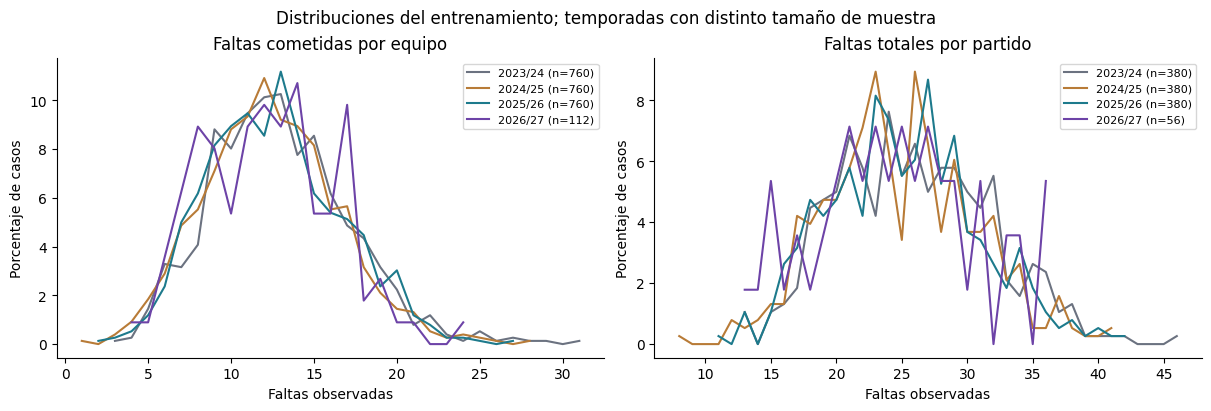

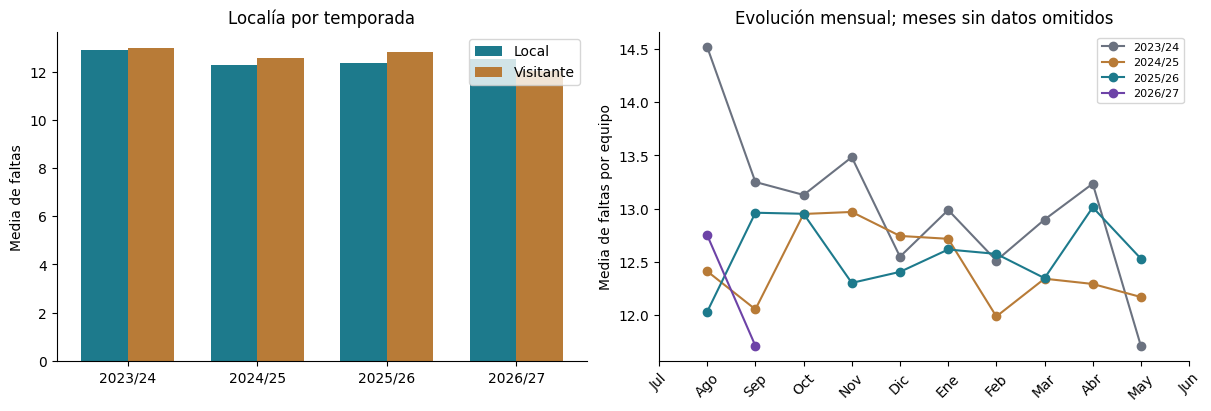

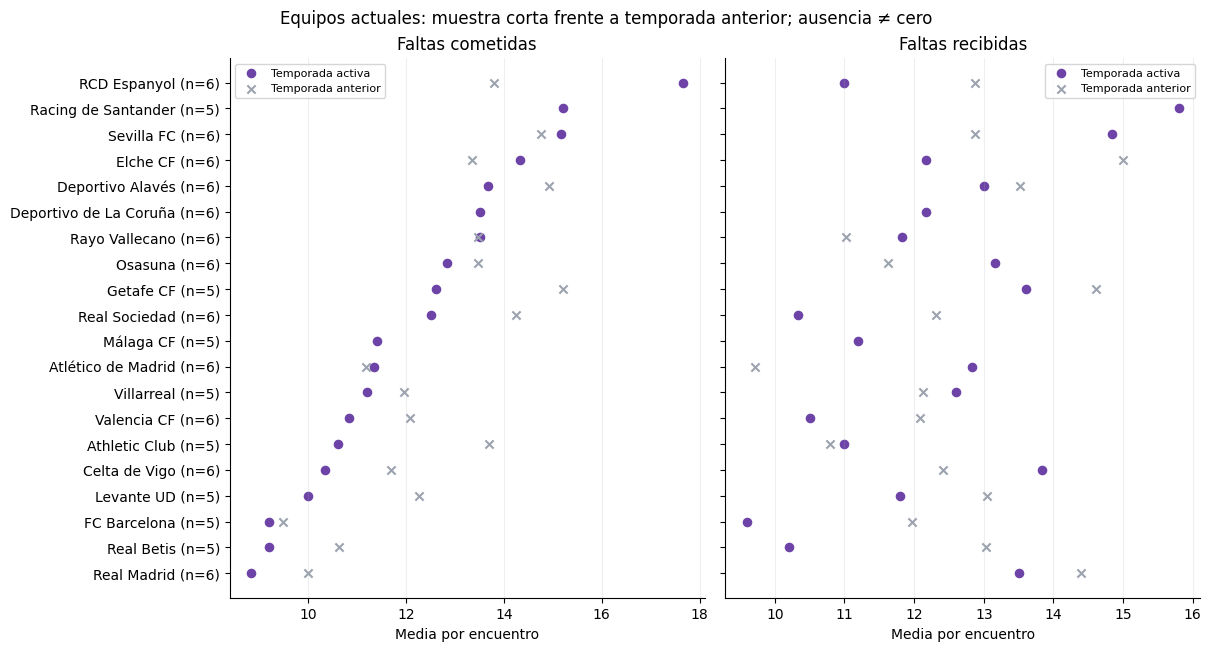

In [6]:
from faltas.investigacion.metodos.exploracion import graficar_exploracion
for nombre,fig in graficar_exploracion(eda).items():
    display(fig)
    plt.close(fig)

<a id="eda-calculo"></a>
**Lectura.** La muestra por club es pequeña y una media distinta todavía no demuestra estabilidad.
Los extremos se conservan. Las columnas vacías requieren un tratamiento explícito y las diferencias
de localía se contrastarán con predicciones posteriores, no solo con gráficos descriptivos.
La prioridad inicial reparte 55/25/13/7 entre temporadas; el 03 comprobará nueve repartos.

<a id="variables"></a>
## 5. Construir 108 variables previas

Calculamos medias de faltas propias y recibidas, últimos cinco partidos, localía, estilo, rival,
enfrentamientos directos y tamaño de muestra. Los grupos K2 se reconstruyen con el pasado de cada corte.
El catálogo completo tiene 108 entradas; el 02 comprueba retirar bloques hasta llegar a global 93
y pareja 29. Las categorías pueden generar más columnas internas después de codificarse.

In [7]:
from faltas.variables import diccionario_variables
e=ctx["e"]
mostrar("Variables generadas y significado", diccionario_variables(e.X))
mostrar("Disponibilidad de los antecedentes", e.control[["fecha_prediccion_utc","n_partidos_disponibles","max_disponibilidad_utilizada_utc"]].tail(8).reset_index())
print("Generadas:",e.X.shape,"Global:",e.Xg.shape,"Pareja sin identidad:",e.Xp.shape)
for campo in ["max_inicio_utilizado_utc","max_disponibilidad_utilizada_utc"]:
    assert (e.control[campo].isna()|e.control[campo].lt(e.control.fecha_prediccion_utc)).all()

campo,tipo,descripcion,regla_temporal,tratamiento_ausencia
es_local,numerica,"Resumen de antecedentes disponibles según entidad, periodo y localía indicados en el nombre",Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,n=0 y media ausente; imputación futura dentro de cada entrenamiento
grupo_equipo,categorica,Categoría K2 reconstruida antes de emitir; Sin perfil si faltan antecedentes,Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,Categoría explícita
grupo_rival,categorica,Categoría K2 reconstruida antes de emitir; Sin perfil si faltan antecedentes,Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,Categoría explícita
cruce_grupos,categorica,Categoría K2 reconstruida antes de emitir; Sin perfil si faltan antecedentes,Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,Categoría explícita
equipo_id,categorica,"Identidad conocida previamente; categoría, nunca magnitud ordinal",Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,Categoría explícita
rival_id,categorica,"Identidad conocida previamente; categoría, nunca magnitud ordinal",Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,Categoría explícita
equipo_actual_n,numerica,"Resumen de antecedentes disponibles según entidad, periodo y localía indicados en el nombre",Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,n=0 y media ausente; imputación futura dentro de cada entrenamiento
equipo_actual_cometidas,numerica,"Resumen de antecedentes disponibles según entidad, periodo y localía indicados en el nombre",Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,n=0 y media ausente; imputación futura dentro de cada entrenamiento
equipo_actual_recibidas,numerica,"Resumen de antecedentes disponibles según entidad, periodo y localía indicados en el nombre",Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,n=0 y media ausente; imputación futura dentro de cada entrenamiento
equipo_ultimos5_n,numerica,Últimos cinco disponibles dentro de la temporada activa; n real registrado,Inicio y disponibilidad anteriores a la emisión; igualdad solo para captura operativa acreditada,n=0 y media ausente; imputación futura dentro de cada entrenamiento


Generadas: (2456, 108) Global: (2456, 93) Pareja sin identidad: (2456, 28)


<a id="preparacion"></a>
## 6. Preparar ausencias y categorías dentro de cada entrenamiento

Las medianas, el vocabulario y el escalado se aprenden exclusivamente con el entrenamiento.
Se añaden indicadores de ausencia y se tratan categorías nuevas. Una columna totalmente vacía
no recibe una mediana inventada; las faltas objetivo nunca se imputan. Poisson requiere escalado,
mientras que los árboles no. Se muestra un ajuste de preparación y su aplicación a una consulta.

In [8]:
from faltas.investigacion.metodos.pipeline import construir_preparacion
from faltas.modelos import catalogo
_,corte,it,iv=cc[-1]
pre=construir_preparacion(catalogo(ctx["X"])).fit(ctx["X"].iloc[it])
z=pre.transform(ctx["X"].iloc[iv])
mostrar("Columnas vacías en este entrenamiento", pd.DataFrame({"campo":pre.columnas_vacias_}))
mostrar("Categorías aprendidas", pd.DataFrame([dict(campo=k,categorias=" | ".join(map(str,v))) for k,v in pre.vocabulario_.items()]))
assert np.isfinite(z.to_numpy()).all()
print("Entrenamiento:",len(it),"Consulta:",len(iv),"Entradas:",pre.n_features_in_,"Salidas:",z.shape[1])

campo
arbitro_actual_total
arbitro_ultimos5_total
arbitro_anterior_total
arbitro_actual_desv_total
arbitro_actual_local
arbitro_actual_visitante


campo,categorias
grupo_equipo,Grupo 1 | Grupo 2 | Sin perfil
grupo_rival,Grupo 1 | Grupo 2 | Sin perfil
cruce_grupos,Grupo 1 / Grupo 1 | Grupo 1 / Grupo 2 | Grupo 1 / Sin perfil | Grupo 2 / Grupo 1 | Grupo 2 / Grupo 2 | Grupo 2 / Sin perfil | Sin perfil / Grupo 1 | Sin perfil / Grupo 2 | Sin perfil / Sin perfil
equipo_id,LL-T-1 | LL-T-10 | LL-T-11 | LL-T-12 | LL-T-13 | LL-T-14 | LL-T-15 | LL-T-157 | LL-T-16 | LL-T-162 | LL-T-17 | LL-T-18 | LL-T-19 | LL-T-2 | LL-T-20 | LL-T-21 | LL-T-26 | LL-T-28 | LL-T-3 | LL-T-31 | LL-T-33 | LL-T-4 | LL-T-49 | LL-T-5 | LL-T-54 | LL-T-6 | LL-T-7 | LL-T-8 | LL-T-9
rival_id,LL-T-1 | LL-T-10 | LL-T-11 | LL-T-12 | LL-T-13 | LL-T-14 | LL-T-15 | LL-T-157 | LL-T-16 | LL-T-162 | LL-T-17 | LL-T-18 | LL-T-19 | LL-T-2 | LL-T-20 | LL-T-21 | LL-T-26 | LL-T-28 | LL-T-3 | LL-T-31 | LL-T-33 | LL-T-4 | LL-T-49 | LL-T-5 | LL-T-54 | LL-T-6 | LL-T-7 | LL-T-8 | LL-T-9
arbitro_id,Desconocido


Entrenamiento: 2452 Consulta: 2 Entradas: 108 Salidas: 284


**Siguiente paso.** Ya tenemos una respuesta definida, datos con controles explícitos y variables
construidas respetando sus fechas. El 02 compara estrategias y comprueba si aumentar complejidad
o especializar el entrenamiento aporta una mejora frente a referencias sencillas.